In [5]:
import pandas as pd
import seaborn as sns
import missingno as msno
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

In [6]:
df=pd.read_csv('/Users/elecas/Documents/TIROCINIO/two_years_history 3.csv')

In [7]:
pd.set_option('display.max_column',None)
display(df)

,station_id,ts,wind_speed_avg,wind_speed_hi,wind_dir_of_hi,wind_chill,solar_rad_hi,deg_days_heat,thw_index,bar,hum_out,temp_out,temp_out_lo,wet_bulb,temp_out_hi,solar_rad_avg,bar_alt,wind_run,solar_energy,dew_point_out,wind_dir_of_prevail,et,air_density,rainfall_in,heat_index_out,thsw_index,rainfall_mm,night_cloud_cover,deg_days_cool,rain_rate_hi_in,emc,rain_rate_hi_mm,abs_press,salinity_last_1,moist_soil_last_1,temp_last_1,bar_trend_3_hr,pressure_last,water_potential_last,direct_reading_last,temp_resistance_last
0,90411,2024-05-25 14:00:00,0.0,4.0,9.0,65.200000,237.0,0.000000,65.020000,30.131,71.0,65.2,64.7,59.306,66.3,86.0,30.131,0.0,7.399759,55.557186,9.0,0.002,0.071063,0.0,65.020000,68.0,0.0,0.795821,0.008333,0.0,13.546,0.0,28.565739,0.739200,30.430000,65.894000,-0.02,30.131,NaN,NaN,NaN
1,90411,2024-05-25 15:00:00,5.0,15.0,9.0,65.600000,450.0,0.000000,65.820000,30.119,75.0,65.6,64.3,60.530,66.3,253.0,30.119,5.0,21.769058,57.460220,10.0,0.007,0.070900,0.0,65.820000,64.0,0.0,0.643591,0.025000,0.0,14.450,0.0,28.554245,0.738800,30.350000,65.912000,-0.02,30.119,NaN,NaN,NaN
2,90411,2024-05-25 16:00:00,8.0,15.0,8.0,62.293830,155.0,0.075000,62.365830,30.117,78.0,63.2,62.6,58.946,64.3,115.0,30.117,8.0,9.895026,56.224586,10.0,0.004,0.071273,0.0,63.272000,62.0,0.0,0.708645,0.000000,0.0,15.714,0.0,28.552330,0.741000,30.360000,65.858000,-0.02,30.117,NaN,NaN,NaN
3,90411,2024-05-25 17:00:00,8.0,17.0,10.0,60.144245,98.0,0.150000,60.188244,30.114,82.0,61.4,61.0,58.046,62.6,68.0,30.114,8.0,5.850972,55.854706,10.0,0.003,0.071527,0.0,61.444000,60.0,0.0,0.613083,0.000000,0.0,17.106,0.0,28.549458,0.737200,30.370000,65.930000,0.00,30.114,NaN,NaN,NaN
4,90411,2024-05-25 18:00:00,7.0,14.0,10.0,60.325500,67.0,0.170833,60.295500,30.121,82.0,60.9,60.6,57.560,61.2,19.0,30.121,7.0,1.634831,55.366497,10.0,0.001,0.071633,0.0,60.870003,58.0,0.0,0.613083,0.000000,0.0,17.086,0.0,28.556162,0.740000,30.350000,65.930000,0.00,30.121,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16876,90411,2026-05-25 09:00:00,3.0,9.0,3.0,73.800000,847.0,0.000000,73.920006,30.516,56.0,73.8,72.7,63.284,74.6,800.0,30.516,3.0,68.834970,57.119770,3.0,0.020,0.070770,0.0,73.920006,87.0,0.0,0.000000,0.366667,0.0,10.274,0.0,28.934483,0.693692,27.438462,66.310769,0.02,30.516,-3.11,0.23,1274.08
16877,90411,2026-05-25 10:00:00,4.0,13.0,1.0,75.600000,921.0,0.000000,75.799995,30.512,55.0,75.6,74.4,64.544,76.7,767.0,30.512,4.0,65.995530,58.293037,2.0,0.020,0.070472,0.0,75.799995,87.0,0.0,0.330845,0.441667,0.0,10.026,0.0,28.930649,0.693769,27.407692,66.338462,0.00,30.512,-3.76,0.38,1274.88
16878,90411,2026-05-25 11:00:00,5.0,14.0,1.0,77.200000,1028.0,0.000000,77.180000,30.501,51.0,77.2,76.4,64.742,78.3,742.0,30.501,5.0,63.844433,57.668472,2.0,0.020,0.070263,0.0,77.180000,88.0,0.0,0.406072,0.508333,0.0,9.350,0.0,28.920115,0.693385,27.415385,66.407692,0.00,30.501,-4.23,0.49,1276.81
16879,90411,2026-05-25 12:00:00,6.0,16.0,3.0,78.700000,1136.0,0.000000,78.574000,30.494,49.0,78.7,77.8,65.300,79.7,1013.0,30.494,6.0,87.162280,57.931880,2.0,0.026,0.070039,0.0,78.574000,89.0,0.0,0.000000,0.570833,0.0,8.976,0.0,28.913408,0.697462,27.369231,66.490769,-0.02,30.494,-4.44,0.52,1281.95


In [8]:

#aggiustiamo l'ordine delle colonne del dataset
nuovo_ordine=[ 'ts','temp_out','temp_out_hi','temp_out_lo','deg_days_heat','deg_days_cool','heat_index_out','thw_index','thsw_index','hum_out','dew_point_out','wet_bulb','rainfall_mm','rain_rate_hi_mm','et','water_potential_last','moist_soil_last_1','temp_last_1','salinity_last_1','temp_resistance_last','direct_reading_last','solar_rad_avg','solar_rad_hi','solar_energy','night_cloud_cover','wind_speed_avg','wind_speed_hi','wind_dir_of_prevail','wind_dir_of_hi','wind_run','wind_chill','bar','bar_alt','abs_press','bar_trend_3_hr', 'air_density', 'emc']
df=df[nuovo_ordine]

      

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16881 entries, 0 to 16880
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ts                    16881 non-null  object 
 1   temp_out              16880 non-null  float64
 2   temp_out_hi           16880 non-null  float64
 3   temp_out_lo           16880 non-null  float64
 4   deg_days_heat         16880 non-null  float64
 5   deg_days_cool         16880 non-null  float64
 6   heat_index_out        16880 non-null  float64
 7   thw_index             16880 non-null  float64
 8   thsw_index            16879 non-null  float64
 9   hum_out               16880 non-null  float64
 10  dew_point_out         16880 non-null  float64
 11  wet_bulb              16880 non-null  float64
 12  rainfall_mm           16880 non-null  float64
 13  rain_rate_hi_mm       16880 non-null  float64
 14  et                    16880 non-null  float64
 15  water_potential_las

In [10]:
#converto la colonna ts in formato datetime e la imposto come indice
df['ts']=pd.to_datetime(df['ts'])
df.set_index('ts', inplace=True)
df.sort_index(inplace=True)


Di seguito si riporta una spiegazione sistematica delle colonne, suddivise per aree tematiche:

## Parametri Termometrici e Indici di Calore

Variabili fondamentali per monitorare lo stress termico e lo sviluppo della vite.

- **temp_out** / **temp_out_hi** / **temp_out_lo**: Temperatura dell'aria attuale, massima e minima nel periodo di campionamento.

- **deg_days_heat** / **deg_days_cool**: Gradi Giorno (GDD). Si utilizzano per calcolare l'accumulo termico necessario alla vite per passare da una fase fenologica all'altra (es. dalla fioritura all'invaiatura).

- **heat_index_out**: Indice di calore; combina temperatura e umidità per valutare la percezione del calore.

- **thw_index** / **thsw_index**: Indici complessi che integrano Temperatura, Umidità, Vento e (nel secondo caso) Radiazione Solare. Sono i migliori indicatori dello stress ambientale complessivo sulla pianta.


## Idrologia, Umidità e Precipitazioni

Essenziali per la gestione dei trattamenti fitosanitari e dello stress idrico.

- **hum_out**: Umidità relativa esterna (%).

- **dew_point_out**: Punto di rugiada. Indica la temperatura alla quale si forma condensa sulle foglie, fattore di rischio per la peronospora.

- **wet_bulb**: Temperatura a bulbo umido. Valuta il potenziale di raffreddamento per evaporazione.

- **rainfall_mm** / **rainfall_in**: Quantità di pioggia cumulata (in millimetri e pollici).

- **rain_rate_hi_mm** / **rain_rate_hi_in**: Intensità massima della precipitazione.

- **et** (Evapotraspirazione): Quantità di acqua che il sistema vigneto (suolo + pianta) perde nell'atmosfera. È il dato principale per decidere quando e quanto irrigare.


## Parametri del Suolo (Pedologia)

- **water_potential_last**: Potenziale idrico del suolo. Misura quanto "sforzo" deve compiere la radice per estrarre acqua. Valori troppo negativi indicano stress idrico.

- **moist_soil_last_1**: Umidità volumetrica del terreno.

- **temp_last_1**: Temperatura del suolo.

- **salinity_last_1**: Salinità del suolo, che influenza la capacità osmotica delle radici.

- **temp_resistance_last** / **direct_reading_last**: Dati tecnici grezzi dei sensori nel suolo, utilizzati per la calibrazione interna.


## Radiazione Solare e Luce

- **solar_rad_avg** / **solar_rad_hi**: Radiazione solare media e massima (W/m^2). Determina l'attività fotosintetica.

- **solar_energy**: Energia solare accumulata (ly o J/m^2).

- **night_cloud_cover**: Stima della copertura nuvolosa notturna, utile per prevedere gelate o inversioni termiche.


## Vento e Pressione Atmosferica

- **wind_speed_avg** / **wind_speed_hi**: Velocità del vento media e massima (raffica). Fondamentali per decidere se effettuare trattamenti (evitare la deriva).

- **wind_dir_of_prevail** / **wind_dir_of_hi**: Direzione prevalente del vento e direzione della raffica massima.

- **wind_run**: "Km di vento" passati sopra la stazione; parametro usato nei calcoli dell'evapotraspirazione.

- **wind_chill**: Raffreddamento da vento; effetto del vento sulla perdita di calore.

- **bar** / **bar_alt** / **abs_press**: Pressione barometrica attuale, corretta per l'altitudine e assoluta.

- **bar_trend_3_hr**: Tendenza della pressione nelle ultime 3 ore (utile per previsioni meteo a brevissimo termine).


## Altri Parametri Fisici

- **air_density**: Densità dell'aria, influenzata da altitudine e temperatura.

- **emc** (Equilibrium Moisture Content): Contenuto di umidità di equilibrio. In viticoltura è utile per capire quanto velocemente si asciugano il legno e la chioma dopo una pioggia.







## Duplicati

In [11]:
#conteggio totale dei duplicati
totale_duplicati=df.duplicated().sum()
print(f'Il numero totale di duplicati è: {totale_duplicati}')

#se vi sono duplicati visualizziamoli
if totale_duplicati>0:
    righe_duplicate=df[df.duplicated(keep=False)]
    display(righe_duplicate.sort_index())

Il numero totale di duplicati è: 0


In [12]:
#i duplicati qui sopra mostrati corispondono a righe che non hanno nessun valore, dunque procedo ad eliminarle
df=df.dropna(how='all') #elimino le righe in cui TUTTI i valori sono duplicati

In [13]:
#adesso controlliamo se vi sono date duplicate
timestamp_duplicati=df.index.duplicated().sum()
print(f'Gli indici duplicati sono: {timestamp_duplicati}')

if timestamp_duplicati>0:
    df_timestamp_duplicati=df[df.index.duplicated(keep=False)]
    display(df_timestamp_duplicati.sort_index())

Gli indici duplicati sono: 0


## Missing Values
Si verifica qui la **Nullity Correlation** (Correlazione di Nullità): l'obiettivo è capire se la mancanza del dato nella Feature 1 si verifica contemporaneamente alla mancanza del dato nel Feature 2.

Se due variabili mancano sistematicamente insieme (correlazione pari a 1), significa quasi certamente che condividono un vincolo fisico (es. si trovano sullo stesso circuito hardware, dipendono dalla stessa batteria, o vengono spente dalla medesima routine software).

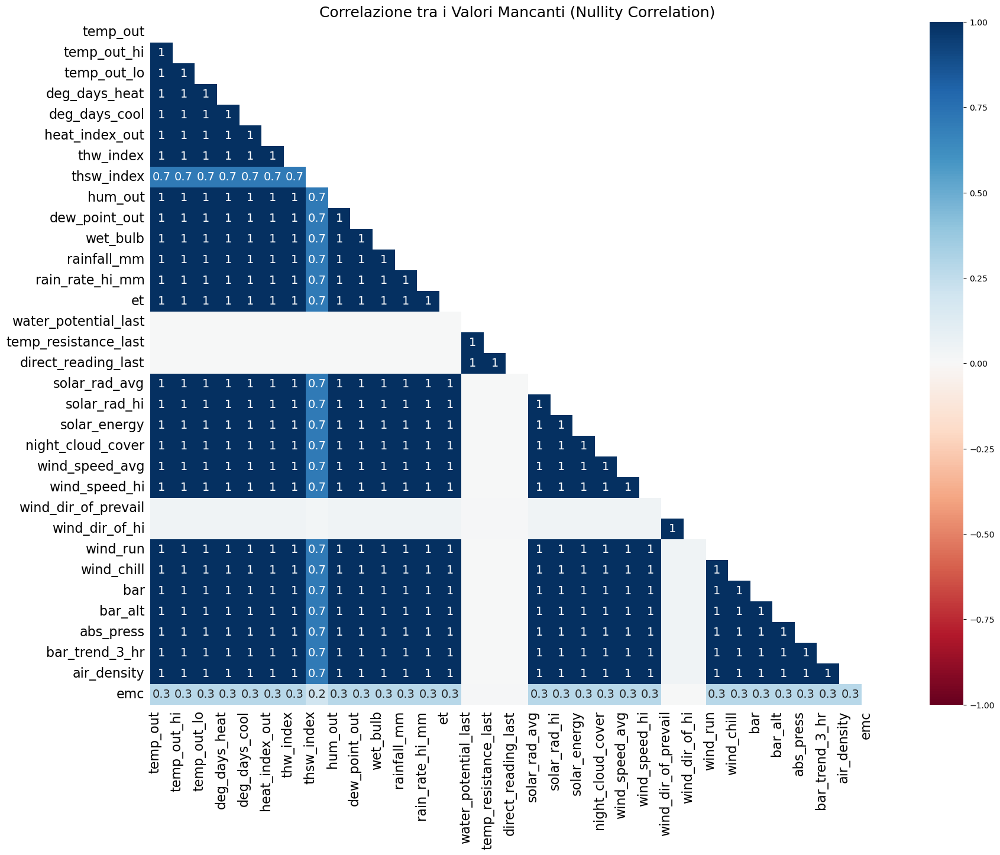

In [14]:
#analizziamo i missing values
# Genera la mappa di correlazione di nullità
# Le colonne senza valori mancanti o totalmente vuote verranno omesse automaticamente
msno.heatmap(df, figsize=(20, 15))
plt.xticks(rotation=90)

plt.title("Correlazione tra i Valori Mancanti (Nullity Correlation)", fontsize=18)
plt.show()

In [15]:
# 1. Creiamo un DataFrame "ombra" dove True = Valore Mancante, False = Valore Presente
df_mancanti = df.isnull()

# 2. Manteniamo solo le colonne che hanno effettivamente almeno un valore mancante
# (non ha senso cercare correlazioni in colonne perfette)
colonne_con_nulli = df_mancanti.columns[df_mancanti.sum() > 0]
df_mancanti_filtrato = df_mancanti[colonne_con_nulli]

# 3. Calcoliamo la matrice di correlazione di Pearson sui valori booleani
matrice_corr_nulli = df_mancanti_filtrato.corr()

# 4. Estraiamo le coppie con forte correlazione (es. maggiore di 0.9)
print("Coppie di variabili che mancano quasi sempre contemporaneamente:")
print("-" * 65)

# Iteriamo sulla matrice per trovare i valori alti, ignorando la diagonale (correlazione di una colonna con se stessa)
for col1 in matrice_corr_nulli.columns:
    for col2 in matrice_corr_nulli.columns:
        if col1 < col2: # Evita duplicati e la diagonale
            correlazione = matrice_corr_nulli.loc[col1, col2]
            if correlazione > 0.9: # Soglia di allarme (90%)
                print(f"[{col1}] e [{col2}] -> Correlazione: {correlazione:.2f}")

Coppie di variabili che mancano quasi sempre contemporaneamente:
-----------------------------------------------------------------
[temp_out] e [temp_out_hi] -> Correlazione: 1.00
[temp_out] e [temp_out_lo] -> Correlazione: 1.00
[temp_out] e [thw_index] -> Correlazione: 1.00
[temp_out] e [wet_bulb] -> Correlazione: 1.00
[temp_out] e [wind_speed_avg] -> Correlazione: 1.00
[temp_out] e [wind_speed_hi] -> Correlazione: 1.00
[temp_out] e [wind_run] -> Correlazione: 1.00
[temp_out] e [wind_chill] -> Correlazione: 1.00
[temp_out_hi] e [temp_out_lo] -> Correlazione: 1.00
[temp_out_hi] e [thw_index] -> Correlazione: 1.00
[temp_out_hi] e [wet_bulb] -> Correlazione: 1.00
[temp_out_hi] e [wind_speed_avg] -> Correlazione: 1.00
[temp_out_hi] e [wind_speed_hi] -> Correlazione: 1.00
[temp_out_hi] e [wind_run] -> Correlazione: 1.00
[temp_out_hi] e [wind_chill] -> Correlazione: 1.00
[temp_out_lo] e [thw_index] -> Correlazione: 1.00
[temp_out_lo] e [wet_bulb] -> Correlazione: 1.00
[temp_out_lo] e [wind_


## Diagnosi finale
La maggior parte dei missing values (gli zeri) sono correlati tra loro, dunque c'è dipendenza statistica tra quelle features.

Tuttavia ci sono le variabili *water_potential_last*, *temp_resistance_last*, *direct_reading_last*, i cui missing values non dipendono da nessuno (forse sono dati che provengono da altri sensori), dato che ci sono solo circa 6 mila valori non nulli, un approccio ideale sarebbe dividere il dataset in 2: la prima parte che contiene queste tre variabili e la seconda che non le contiene, per capire se i missing values provengono dal fatto che in una certa data sono stati messi dei nuovi sensori, visualizziamo l'andamento di queste tre variabili nel tempo.

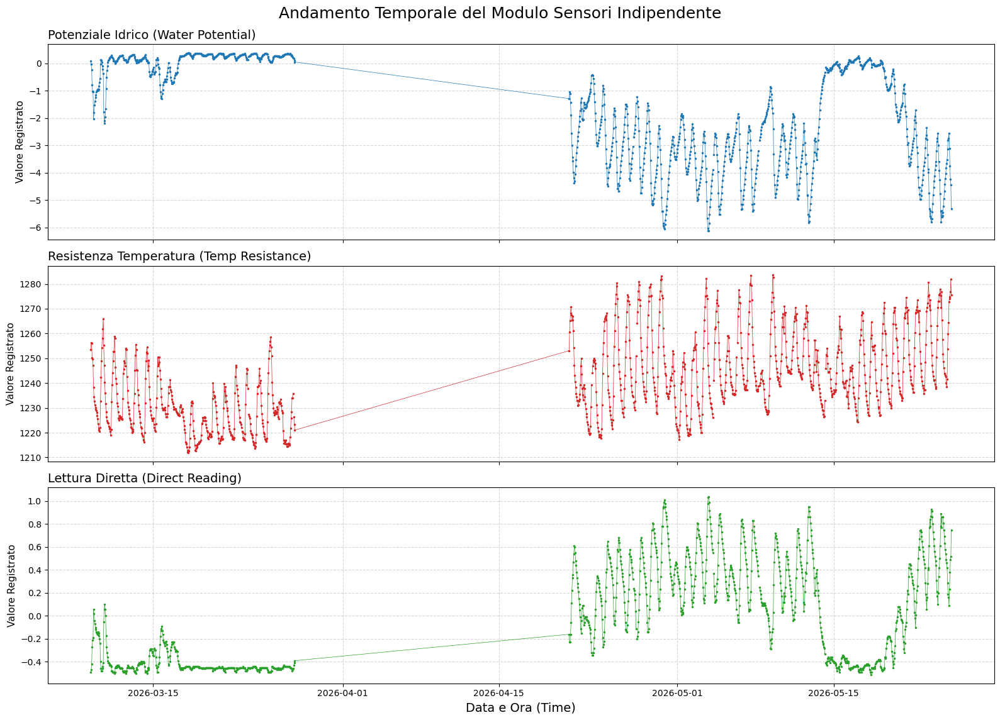

In [16]:
#Definiamo le tre colonne di interesse
colonne_suolo = ['water_potential_last', 'temp_resistance_last', 'direct_reading_last']

# sharex=True assicura che lo zoom temporale sia sincronizzato su tutti e tre i grafici
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True)


colori = ['#1f77b4', '#d62728', '#2ca02c']
titoli = ['Potenziale Idrico (Water Potential)', 
          'Resistenza Temperatura (Temp Resistance)', 
          'Lettura Diretta (Direct Reading)']

# per popolare ciascun grafico
for i, colonna in enumerate(colonne_suolo):
    
    dati_validi = df[colonna]
    
    
    axes[i].plot(dati_validi.index, dati_validi, 
                 color=colori[i], marker='.', linestyle='-', 
                 linewidth=0.5, markersize=3)
    
    # Formattazione del singolo grafico
    axes[i].set_title(titoli[i], fontsize=14, loc='left')
    axes[i].set_ylabel('Valore Registrato', fontsize=11)
    axes[i].grid(True, linestyle='--', alpha=0.5)

#Formattazione generale
plt.suptitle('Andamento Temporale del Modulo Sensori Indipendente', fontsize=18, y=0.95)
plt.xlabel('Data e Ora (Time)', fontsize=14)

# Ottimizza gli spazi tra i grafici per evitare sovrapposizioni di testo
plt.tight_layout()
plt.subplots_adjust(top=0.90) # Lascia spazio per il super-titolo

# Visualizzazione
plt.show()

ok dunque i missing value precedenti sono sicuramente correlati al fatto che viene inserito un nuovo sensore che prende queste tre misurazioni (a esclusione dei missing values nella zona a destra del grafico che forse sono dovuti allo spegnimento dei sensori o a un guasto)

--- Riassunto Esatto dei Valori Mancanti (NaN) ---
Totale righe nel dataset: 16881

                      Conteggio_NaN  Percentuale_NaN (%)
direct_reading_last           15633               92.607
water_potential_last          15633               92.607
temp_resistance_last          15633               92.607
wind_dir_of_hi                  545                3.228
wind_dir_of_prevail             545                3.228
emc                              13                0.077
thsw_index                        2                0.012
thw_index                         1                0.006
night_cloud_cover                 1                0.006
air_density                       1                0.006
bar_trend_3_hr                    1                0.006
abs_press                         1                0.006
bar_alt                           1                0.006
bar                               1                0.006
wind_chill                        1                0.006
wind

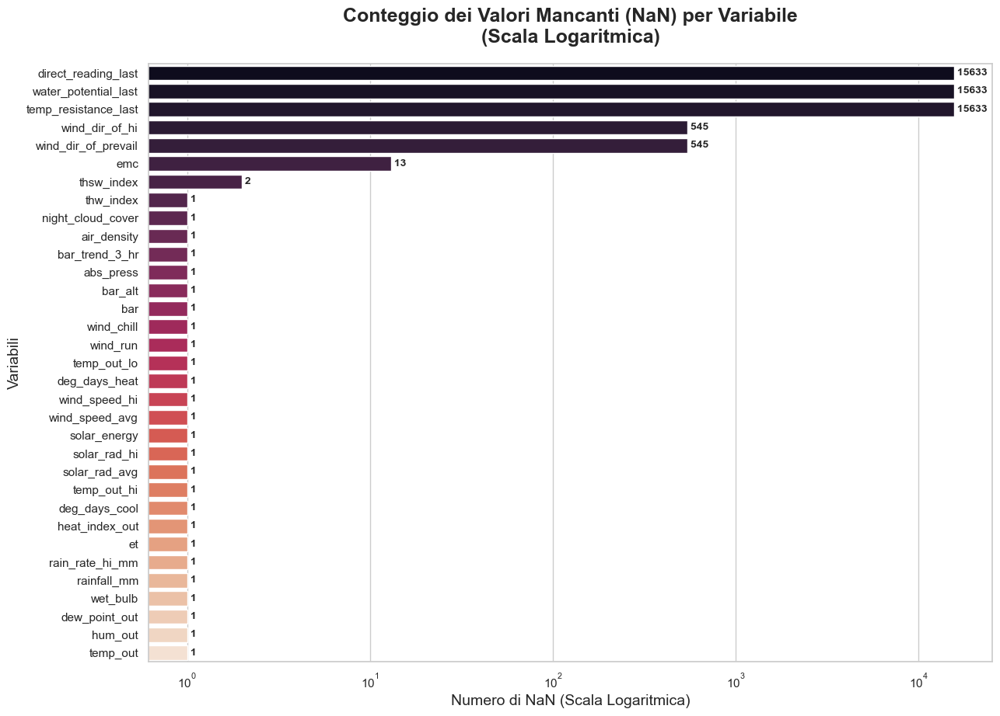

In [17]:
total_rows = len(df)

# Calcolo esatto dei valori mancanti (NaN) per ogni colonna
nan_counts = df.isnull().sum()
nan_counts = nan_counts[nan_counts > 0].sort_values(ascending=False)
nan_pct = (nan_counts / total_rows) * 100

# Creazione di un DataFrame riassuntivo
nan_summary = pd.DataFrame({
    'Conteggio_NaN': nan_counts, 
    'Percentuale_NaN (%)': nan_pct.round(3)
})

print("--- Riassunto Esatto dei Valori Mancanti (NaN) ---")
print(f"Totale righe nel dataset: {total_rows}\n")
print(nan_summary)

# Generazione di un grafico a barre 
plt.figure(figsize=(14, 10))
sns.set_theme(style="whitegrid")

# Utilizziamo una scala logaritmica per l'asse X a causa dell'enorme differenza tra i sensori rotti (>10k) e quelli con pochi NaN (5)
ax = sns.barplot(x=nan_counts.values, y=nan_counts.index, palette='rocket', hue=nan_counts.index, legend=False)
ax.set_xscale("log")

plt.title("Conteggio dei Valori Mancanti (NaN) per Variabile\n(Scala Logaritmica)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("Numero di NaN (Scala Logaritmica)", fontsize=14)
plt.ylabel("Variabili", fontsize=14)

# Aggiunta dei valori numerici esatti sulle barre
for i, v in enumerate(nan_counts.values):
    ax.text(v, i, f" {v}", va='center', fontsize=10, fontweight='bold')
plt.show()

\
Le variabili *temp_resistance_last*, *direct_reading_last*, *water_potential_last* hanno dati mancanti per oltre la metà del dataset (circa il 60%), pertanto ai fini della modellizzazione per l'irrigazione queste colonne sono matematicamente inutilizzabili (l'algoritmo non avrebbe dati sufficienti per imparare il loro comportamento), quindi escludiamo queste tre variabili dal dataset.

Per quanto riguarda le altre features, esse hanno al di sotto del 3% dei valori mancanti, pertanto si procede con l'eliminazione delle righe in cui vi è stato il blackout dei sensori.

In [18]:
colonne_da_rimuovere = ['temp_resistance_last', 'direct_reading_last', 'water_potential_last']
df_clean = df.drop(columns=colonne_da_rimuovere, errors='ignore')

# Rimozione delle righe "blackout" (dove tutti i sensori meteorologici sono NaN)
colonne_sensori = [col for col in df_clean.columns]
df_clean = df_clean.dropna(subset=colonne_sensori, how='all')

df_clean = df_clean.sort_values(by='ts') # Assicuriamoci che sia in ordine cronologico
df_clean = df_clean.ffill()

# Controllo finale
nan_rimanenti = df_clean.isnull().sum().sum()
print(f"Dimensioni dopo la pulizia: {df_clean.shape}")
print(f"Totale NaN rimanenti nel dataset: {nan_rimanenti}")
display(df_clean)

Dimensioni dopo la pulizia: (16881, 33)
Totale NaN rimanenti nel dataset: 0


,temp_out,temp_out_hi,temp_out_lo,deg_days_heat,deg_days_cool,heat_index_out,thw_index,thsw_index,hum_out,dew_point_out,wet_bulb,rainfall_mm,rain_rate_hi_mm,et,moist_soil_last_1,temp_last_1,salinity_last_1,solar_rad_avg,solar_rad_hi,solar_energy,night_cloud_cover,wind_speed_avg,wind_speed_hi,wind_dir_of_prevail,wind_dir_of_hi,wind_run,wind_chill,bar,bar_alt,abs_press,bar_trend_3_hr,air_density,emc
ts,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-05-25 14:00:00,65.2,66.3,64.7,0.000000,0.008333,65.020000,65.020000,68.0,71.0,55.557186,59.306,0.0,0.0,0.002,30.430000,65.894000,0.739200,86.0,237.0,7.399759,0.795821,0.0,4.0,9.0,9.0,0.0,65.200000,30.131,30.131,28.565739,-0.02,0.071063,13.546
2024-05-25 15:00:00,65.6,66.3,64.3,0.000000,0.025000,65.820000,65.820000,64.0,75.0,57.460220,60.530,0.0,0.0,0.007,30.350000,65.912000,0.738800,253.0,450.0,21.769058,0.643591,5.0,15.0,10.0,9.0,5.0,65.600000,30.119,30.119,28.554245,-0.02,0.070900,14.450
2024-05-25 16:00:00,63.2,64.3,62.6,0.075000,0.000000,63.272000,62.365830,62.0,78.0,56.224586,58.946,0.0,0.0,0.004,30.360000,65.858000,0.741000,115.0,155.0,9.895026,0.708645,8.0,15.0,10.0,8.0,8.0,62.293830,30.117,30.117,28.552330,-0.02,0.071273,15.714
2024-05-25 17:00:00,61.4,62.6,61.0,0.150000,0.000000,61.444000,60.188244,60.0,82.0,55.854706,58.046,0.0,0.0,0.003,30.370000,65.930000,0.737200,68.0,98.0,5.850972,0.613083,8.0,17.0,10.0,10.0,8.0,60.144245,30.114,30.114,28.549458,0.00,0.071527,17.106
2024-05-25 18:00:00,60.9,61.2,60.6,0.170833,0.000000,60.870003,60.295500,58.0,82.0,55.366497,57.560,0.0,0.0,0.001,30.350000,65.930000,0.740000,19.0,67.0,1.634831,0.613083,7.0,14.0,10.0,10.0,7.0,60.325500,30.121,30.121,28.556162,0.00,0.071633,17.086
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-05-25 09:00:00,73.8,74.6,72.7,0.000000,0.366667,73.920006,73.920006,87.0,56.0,57.119770,63.284,0.0,0.0,0.020,27.438462,66.310769,0.693692,800.0,847.0,68.834970,0.000000,3.0,9.0,3.0,3.0,3.0,73.800000,30.516,30.516,28.934483,0.02,0.070770,10.274
2026-05-25 10:00:00,75.6,76.7,74.4,0.000000,0.441667,75.799995,75.799995,87.0,55.0,58.293037,64.544,0.0,0.0,0.020,27.407692,66.338462,0.693769,767.0,921.0,65.995530,0.330845,4.0,13.0,2.0,1.0,4.0,75.600000,30.512,30.512,28.930649,0.00,0.070472,10.026
2026-05-25 11:00:00,77.2,78.3,76.4,0.000000,0.508333,77.180000,77.180000,88.0,51.0,57.668472,64.742,0.0,0.0,0.020,27.415385,66.407692,0.693385,742.0,1028.0,63.844433,0.406072,5.0,14.0,2.0,1.0,5.0,77.200000,30.501,30.501,28.920115,0.00,0.070263,9.350


In [19]:
import plotly.express as px


colonne_termometriche = ['temp_out','temp_out_hi','temp_out_lo','deg_days_heat','deg_days_cool','heat_index_out','thw_index','thsw_index']

# Genera il grafico interattivo
fig = px.line(df, y=colonne_termometriche, title='Esplorazione Interattiva Variabili Termometriche', width=1200, height=2000)

# Imposta i punti e le linee sottili come in Matplotlib
fig.update_traces(mode='markers+lines', marker=dict(size=3), line=dict(width=1))

# Mostra il grafico 
fig.show()

In [20]:
colonne_idrologia_umidita_pioggia=['hum_out','dew_point_out','wet_bulb','rainfall_mm','rain_rate_hi_mm','et']
fig = px.line(df, y=colonne_idrologia_umidita_pioggia, title='Esplorazione Interattiva Variabili ', width=1200, height=2000)
fig.update_traces(mode='markers+lines', marker=dict(size=3), line=dict(width=1))
fig.show()

In [21]:
colonne_suolo=['water_potential_last','moist_soil_last_1','temp_last_1','salinity_last_1','temp_resistance_last','direct_reading_last']
fig = px.line(df, y=colonne_suolo, title='Esplorazione Interattiva Variabili ', width=1200, height=2000)
fig.update_traces(mode='markers+lines', marker=dict(size=3), line=dict(width=1))
fig.show()

               

In [22]:
colonne_radiazione_solare=['solar_rad_avg','solar_rad_hi','solar_energy','night_cloud_cover']
fig = px.line(df, y=colonne_radiazione_solare, title='Esplorazione Interattiva Variabili ', width=1200, height=2000)
fig.update_traces(mode='markers+lines', marker=dict(size=3), line=dict(width=1))
fig.show()

In [23]:
colonne_vento_press_atm=['wind_speed_avg','wind_speed_hi','wind_dir_of_prevail','wind_dir_of_hi','wind_run','wind_chill','bar','bar_alt','abs_press','bar_trend_3_hr', 'air_density', 'emc']
fig = px.line(df, y=colonne_vento_press_atm, title='Esplorazione Interattiva Variabili ', width=1200, height=2000)
fig.update_traces(mode='markers+lines', marker=dict(size=3), line=dict(width=1))
fig.show()

Ad occhio si vede che tra marzo e aprile 2026 vi è un buco temporale, cioè non sono state prese misurazioni. Nel dataset queste righe non ci sono quindi ok.



Adesso analizziamo gli zeri, in generale la presenza di zeri in un dataset meteorologico rappresenta un dato valido e misurato.

Lo zero non indica l'assenza dell'informazione, bensì attesta che l'intensità del fenomeno atmosferico in quel momento era nulla.

Adesso ai fini esplorativi calcoliamo il numero e la percentuale di zeri per ogni colonna.

In [24]:
# Calcolo del numero e della percentuale di zeri per ogni colonna
zeros_count = (df_clean == 0).sum()
zeros_pct = (zeros_count / len(df_clean)) * 100

# Creazione di un DataFrame riassuntivo
zeros_summary = pd.DataFrame({'Conteggio_Zeri': zeros_count, 'Percentuale_Zeri': zeros_pct})

# Filtraggio e ordinamento (solo colonne con zeri, in ordine decrescente)
zeros_summary = zeros_summary[zeros_summary['Conteggio_Zeri'] > 0].sort_values('Percentuale_Zeri', ascending=False)

print("--- Variabili con la maggiore incidenza di Zeri ---")
print(zeros_summary.head(39))



--- Variabili con la maggiore incidenza di Zeri ---
                     Conteggio_Zeri  Percentuale_Zeri
rain_rate_hi_mm               16050         95.077306
rainfall_mm                   15728         93.169836
deg_days_cool                 10974         65.007997
bar_trend_3_hr                 8685         51.448374
solar_rad_avg                  7870         46.620461
solar_energy                   7870         46.620461
solar_rad_hi                   7762         45.980688
deg_days_heat                  5937         35.169717
et                             3908         23.150287
night_cloud_cover              3742         22.166933
wind_speed_avg                 2888         17.107991
wind_run                       2888         17.107991
wind_dir_of_prevail            1065          6.308868
wind_dir_of_hi                 1004          5.947515
wind_speed_hi                   544          3.222558


1. **Il Blocco delle Precipitazioni** 

Le variabili relative alla pioggia sono quelle che presentano in assoluto la maggior quantità di zeri:

- *rainfall_mm*  (Quantità di pioggia): presentano zeri nel 93.1% dei casi.

- *rain_rate_hi_mm* (Intensità massima di pioggia): presenta zeri nel 95.00% dei casi.

**Motivazione**: Questo risultato è del tutto fisiologico. Indica semplicemente che per il 93% delle ore monitorate nei due anni di riferimento, non ha piovuto. In quasi tutti i climi (fatta eccezione per le foreste pluviali), i periodi di tempo asciutto superano di gran lunga i periodi di precipitazione attiva.




2. **Variabili Termiche**

- *deg_days_cool* (Gradi Giorno di Raffreddamento): 64.9% di zeri.

- *deg_days_heat* (Gradi Giorno di Riscaldamento): 35.2% di zeri.

**Motivazione**: I "gradi giorno" sono indicatori utilizzati in climatologia ed energetica per stimare il fabbisogno di riscaldamento o raffreddamento degli edifici. Si calcolano solo quando la temperatura esterna supera (o scende al di sotto) di una certa soglia di comfort prestabilita (generalmente intorno ai 18°C o 65°F). Se la temperatura della giornata si mantiene all'interno della fascia "neutra", o se la stagione è opposta (es. fa freddo, quindi il fabbisogno di raffreddamento è nullo), il valore registrato sarà esattamente zero.


3. **Il Blocco Eolico**

- *wind_speed_avg* e *wind_run*: presentano zeri nel 17.15% dei casi.

**Motivazione**: Questi zeri indicano le ore di "calma di vento" (o vento assente), in cui la velocità media dell'aria non è stata sufficiente a far ruotare l'anemometro della stazione.

4. **Stabilità Barometrica**

- bar_trend_3_hr (Tendenza barometrica a 3 ore): presenta il 51.5% di zeri.

**Motivazione**: Indica che, per oltre la metà del tempo, la variazione della pressione atmosferica nell'arco di tre ore è stata nulla (pressione stabile).


In conclusione, la presenza degli zeri nel dataset non è indice di corruzione dei dati, ma fotografa in modo fedele e accurato la natura ciclica ed episodica dei fenomeni meteorologici (la notte, i periodi di siccità, l'assenza di vento).

In [25]:
# Approfondimento Radiazione Solare: estrazione dell'ora direttamente dall'indice
df_clean['hour'] = df_clean.index.hour
solar_zeros_by_hour = df_clean[df_clean['solar_rad_avg'] == 0]['hour'].value_counts().sort_index()

print("\n--- Distribuzione degli zeri per 'solar_rad_avg' in base all'ora (UTC) ---")
print(solar_zeros_by_hour)

# Rimozione della colonna d'appoggio 'hour' per mantenere pulito il dataset (opzionale)
df_clean = df_clean.drop(columns=['hour'])


--- Distribuzione degli zeri per 'solar_rad_avg' in base all'ora (UTC) ---
hour
0     703
1     703
2     703
3     703
4     549
5     372
6     194
7       5
8       1
12      1
16      7
17    199
18    377
19    541
20    703
21    703
22    703
23    703
Name: count, dtype: int64


\
**Il Blocco della Radiazione Solare**

Le metriche legate all'irraggiamento solare presentano un'incidenza di zeri pari a quasi la metà del dataset:

- *solar_rad_avg*, *solar_energy*, *solar_rad_hi*: si attestano intorno al 46% - 46.5% di valori pari a zero.

**Motivazione** : Per verificare questa ipotesi, abbiamo calcolato la distribuzione oraria degli zeri per la variabile *solar_rad_avg*. Come prevedibile, gli zeri si concentrano esclusivamente durante le ore notturne. Dalle 20:00 alle 03:00 (UTC) il valore è costantemente pari a zero per quasi tutti i giorni dell'anno. Inizia poi a diminuire gradualmente all'alba (ore 04:00 - 06:00 UTC) e scompare del tutto nelle ore centrali della giornata (dalle 08:00 alle 15:00 UTC), per poi ricomparire al tramonto (dalle 17:00 in poi).

*Nota aggiuntiva*: Durante le ore diurne, un valore pari a zero si registra solo in casi eccezionali, come ad esempio una copertura nuvolosa estremamente densa, un malfunzionamento del pirometro o, più raramente, un'eclissi solare.

## Analisi Grafica

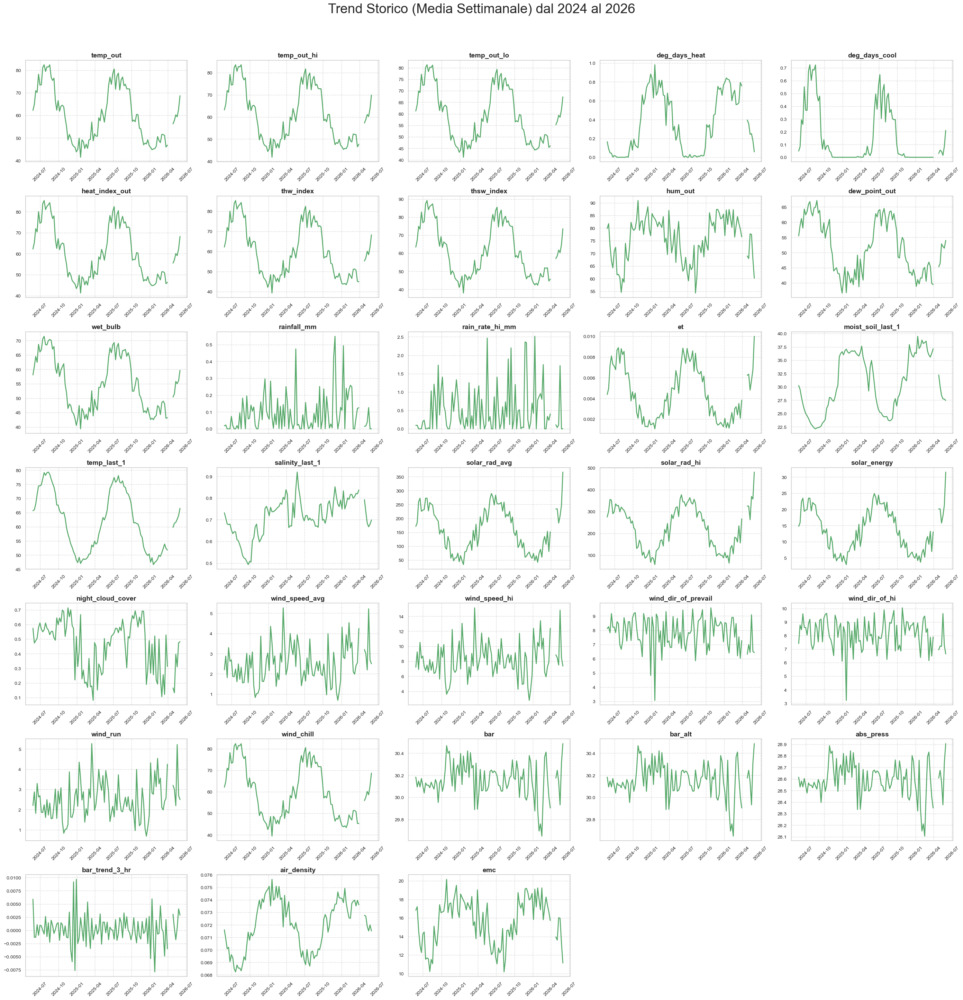

In [26]:
# --- Serie Storiche (Trend Settimanale per leggibilità) ---
# Aggreghiamo i dati su base settimanale (media) per smussare il rumore orario
df_weekly = df_clean.resample('W').mean()

fig, axes = plt.subplots(nrows=8, ncols=5, figsize=(28, 35))
axes = axes.flatten()

for i, col in enumerate(df_weekly.columns):
    axes[i].plot(df_weekly.index, df_weekly[col], color='#55A868', linewidth=2)
    axes[i].set_title(col, fontsize=14, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45, labelsize=10)
    axes[i].tick_params(axis='y', labelsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.7)

# Nascondiamo i subplot vuoti se ci sono
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Trend Storico (Media Settimanale) dal 2024 al 2026", fontsize=28, y=0.92)
plt.tight_layout(rect=[0, 0, 1, 0.9])

## Outliers Check

--- Riassunto degli Outliers (Metodo IQR) ---
                 Conteggio_Outliers  Percentuale_Outliers
bar_trend_3_hr                 8196             48.551626
deg_days_cool                  2271             13.452994
et                             1925             11.403353
solar_rad_avg                  1544              9.146378
solar_energy                   1544              9.146378
rainfall_mm                    1153              6.830164
rain_rate_hi_mm                 831              4.922694
abs_press                       597              3.536520
bar_alt                         597              3.536520
bar                             597              3.536520
wind_speed_avg                  431              2.553166
wind_run                        431              2.553166
solar_rad_hi                    215              1.273621
wind_speed_hi                   165              0.977430
thsw_index                      124              0.734554


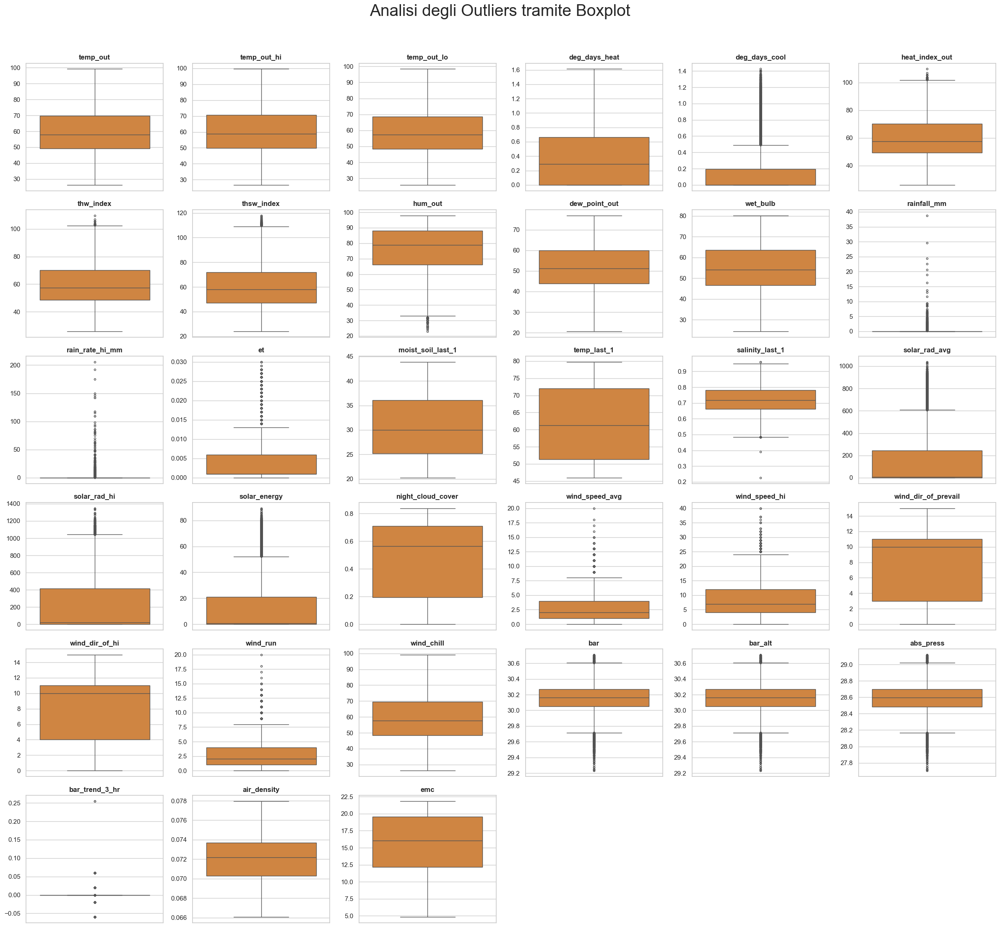


Grafico dei boxplot generato con successo.


In [27]:

# Calcolo degli outliers usando il metodo IQR (Interquartile Range)
Q1 = df_clean.quantile(0.25)
Q3 = df_clean.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = ((df_clean < lower_bound) | (df_clean > upper_bound)).sum()
outliers_pct = (outliers_count / len(df_clean)) * 100

outliers_summary = pd.DataFrame({'Conteggio_Outliers': outliers_count, 'Percentuale_Outliers': outliers_pct})
outliers_summary = outliers_summary[outliers_summary['Conteggio_Outliers'] > 0].sort_values('Percentuale_Outliers', ascending=False)

print("--- Riassunto degli Outliers (Metodo IQR) ---")
print(outliers_summary.head(15))

# Generazione dei Boxplot
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=6, ncols=6, figsize=(24, 24))
axes = axes.flatten()

for i, col in enumerate(df_clean.columns):
    sns.boxplot(y=df_clean[col], ax=axes[i], color='#E6842A', fliersize=3, linewidth=1)
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('')

# Nascondi assi vuoti
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Analisi degli Outliers tramite Boxplot", fontsize=28, y=0.92)
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()
print("\nGrafico dei boxplot generato con successo.")

Per verificare se gli "outliers" sono normali devo vedere le correlazioni tra le variabili

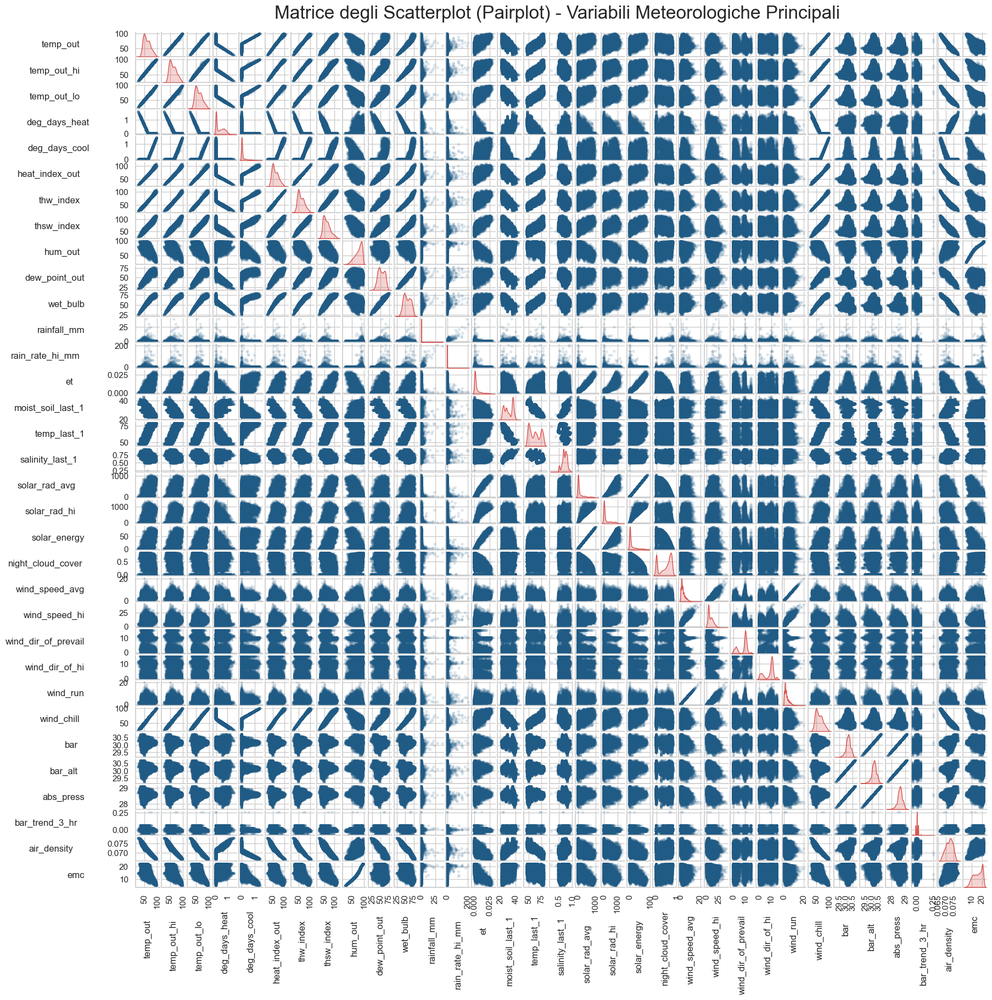

In [28]:

#vediamo prima lo scatterplot per decidere il tipo di correlazione da verificare
pairplot = sns.pairplot(df_clean, 
                        
                        diag_kind='kde', 
                        plot_kws={'alpha': 0.15, 's': 15, 'edgecolor': 'none', 'color': '#205B85'},
                        diag_kws={'color': '#D9534F'})

# Titolo e formattazione
pairplot.fig.suptitle("Matrice degli Scatterplot (Pairplot) - Variabili Meteorologiche Principali", fontsize=24, y=1.02)
pairplot.fig.set_size_inches(16, 16)

# Iterazione sugli assi per ruotare le etichette (sia i valori numerici che i nomi delle variabili)
for ax in pairplot.axes.flatten():
    if ax is not None:
        # Rotazione dei valori numerici (tick labels)
        ax.tick_params(axis='x', rotation=90)
        ax.tick_params(axis='y', rotation=0)
        
        # Rotazione dei nomi delle variabili (axis labels)
        xlabel = ax.get_xlabel()
        if xlabel:
            ax.set_xlabel(xlabel, rotation=90, labelpad=15)
            
        ylabel = ax.get_ylabel()
        if ylabel:
            # ha='right' (horizontal alignment) garantisce che il testo non si sovrapponga all'asse
            ax.set_ylabel(ylabel, rotation=0, labelpad=45, ha='right', va='center')
plt.show()

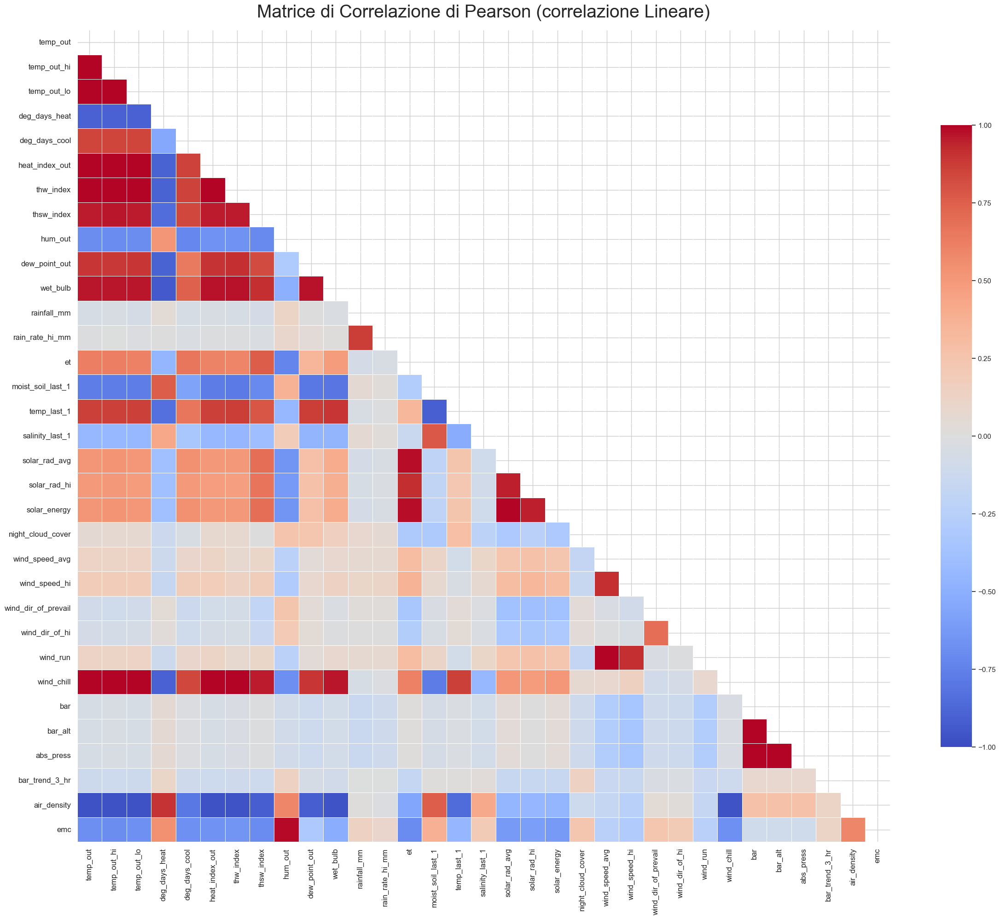

In [29]:
# --- Matrice di Correlazione Pearson ---
plt.figure(figsize=(24, 20))
corr = df_clean.corr()

# Maschera per la metà superiore della matrice 
mask = pd.DataFrame(False, index=corr.index, columns=corr.columns)
import numpy as np
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .75})
plt.title("Matrice di Correlazione di Pearson (correlazione Lineare)", fontsize=28, pad=20)
plt.xticks(rotation=90, fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

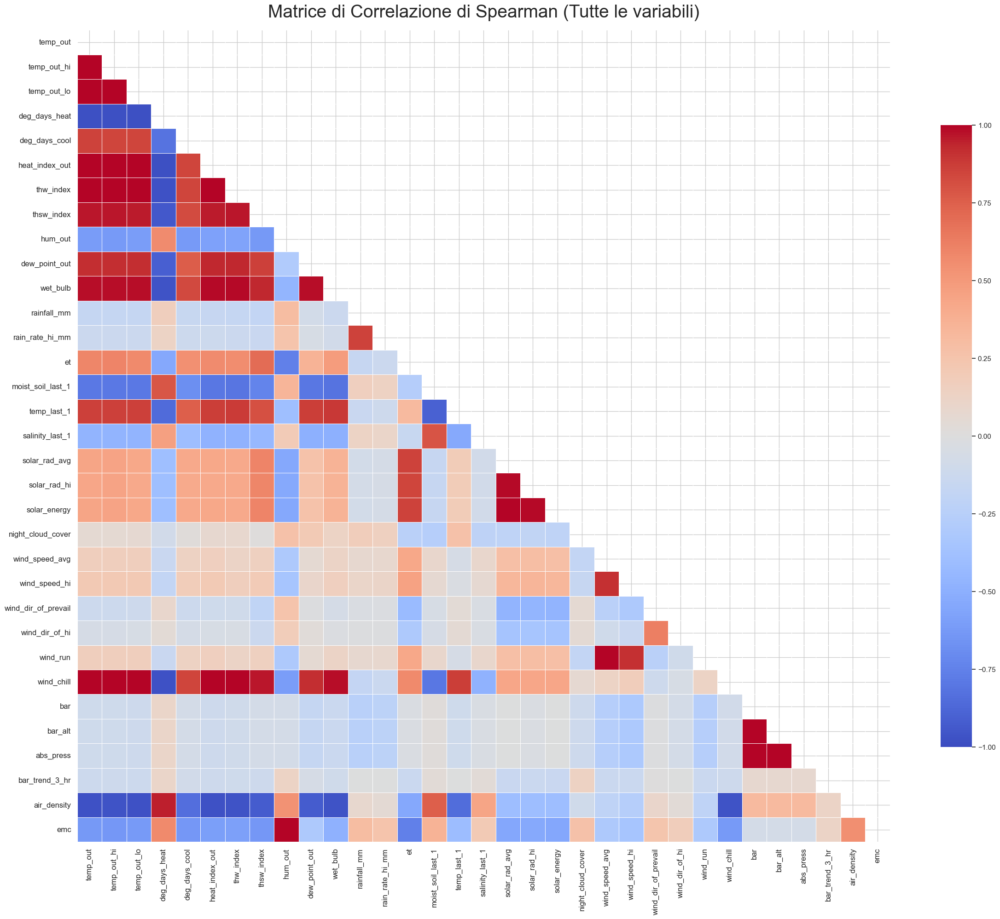

In [30]:
#--- Matrice di Correlazione di Spearman ---
# Calcolo della matrice di correlazione di Spearman
corr_spearman = df_clean.corr(method='spearman')

# Creazione della Heatmap
plt.figure(figsize=(24, 20))

# Maschera per triangolo superiore
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))


sns.heatmap(corr_spearman, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .75})

plt.title("Matrice di Correlazione di Spearman (Tutte le variabili)", fontsize=28, pad=20)
plt.xticks(rotation=90, fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

Non sembrano esserci outliers importanti

## Smart Irrigation
L'**Evapotraspirazione** è la variabile agronomica per eccellenza. 

Essa calcola (tramite formule complesse che incrociano temperatura, radiazione solare, vento e umidità) quanta acqua in millimetri il sistema "suolo + pianta" ha perso nell'atmosfera in quella determinata ora. È, di fatto, la "sete" della pianta. Più alto è il valore, più acqua è stata consumata.

L'Evapotraspirazione non è una grandezza che si misura con un singolo sensore diretto (come la pioggia o la temperatura), bensì è un valore calcolato dalla centralina meteo.

L'ET è, di fatto, un "riassunto" matematico di tutte le altre variabili atmosferiche.

*Quali sono i fattori meteorologici che determinano quanta "sete" ha la pianta?*


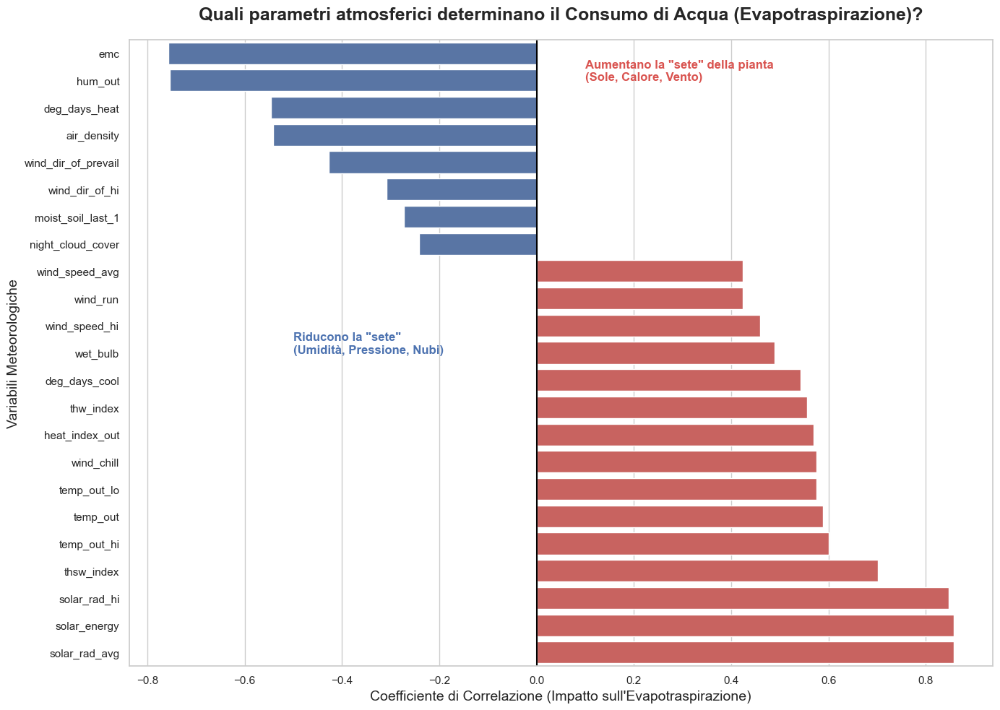

In [31]:
# Calcoliamo le correlazioni dirette dell'Evapotraspirazione (ET) con le altre variabili
et_corr = df_clean.corr(method='spearman')['et'].drop('et')

# Separiamo i fattori che aumentano il consumo di acqua (correlazione positiva)
# e quelli che lo riducono (correlazione negativa)
top_positive = et_corr.sort_values(ascending=False).head(15)
top_negative = et_corr.sort_values(ascending=True).head(8)

# Uniamo per il grafico
et_factors = pd.concat([top_positive, top_negative]).sort_values()

# Creazione del grafico a barre orizzontali
plt.figure(figsize=(14, 10))
sns.set_theme(style="whitegrid")

# Colori: Rosso per fattori che aumentano la sete, Blu per quelli che la riducono
colors = ['#4C72B0' if x < 0 else '#D9534F' for x in et_factors.values]

ax = sns.barplot(x=et_factors.values, y=et_factors.index, palette=colors , hue=et_factors.index)

plt.title("Quali parametri atmosferici determinano il Consumo di Acqua (Evapotraspirazione)?", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("Coefficiente di Correlazione (Impatto sull'Evapotraspirazione)", fontsize=14)
plt.ylabel("Variabili Meteorologiche", fontsize=14)

# Aggiunta di annotazioni per chiarezza
plt.axvline(0, color='black', linewidth=1.5)
plt.text(0.1, 1, 'Aumentano la "sete" della pianta \n(Sole, Calore, Vento)', fontsize=12, color='#D9534F', fontweight='bold')
plt.text(-0.5, 11, 'Riducono la "sete" \n(Umidità, Pressione, Nubi)', fontsize=12, color='#4C72B0', fontweight='bold')

plt.tight_layout()
plt.show()

Il Sole risulta la variabile dominante che determina la sete della pianta.

Ma come è possibile che non ci sia dipendenza dalla pioggia?

Non ci si può affidare solo alla statistica classica quindi applichiamo un po' di machine learning.


--- Performance sul Test Set ---
R-quadro (R2): 0.993 
Errore Medio Assoluto (MAE): 0.00 


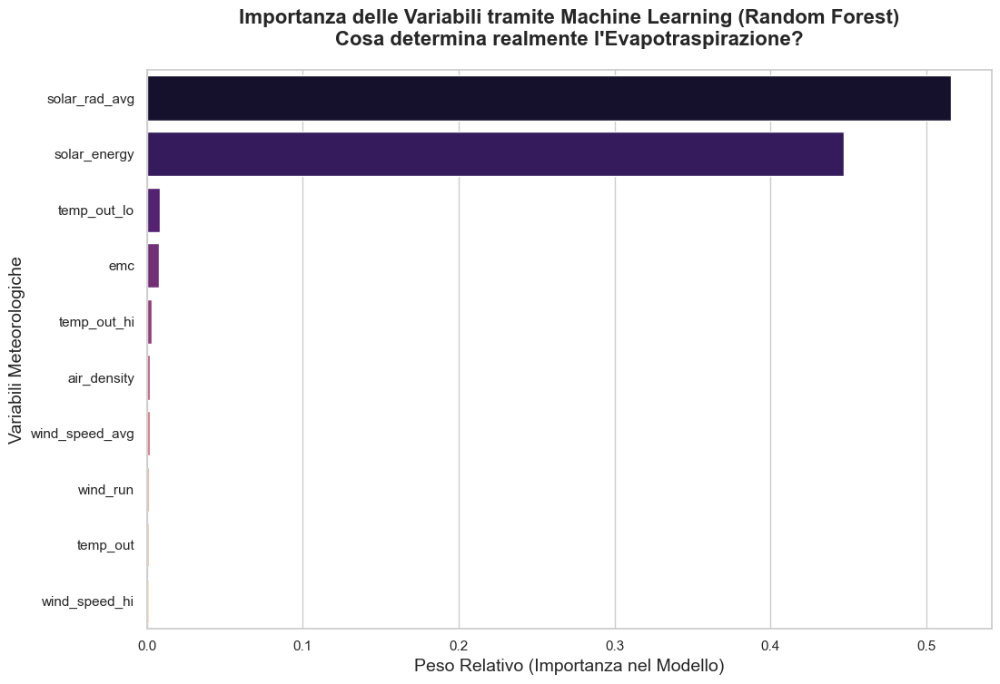


Top 5 variabili più importanti secondo il Machine Learning:
solar_rad_avg    0.515916
solar_energy     0.447126
temp_out_lo      0.008588
emc              0.007947
temp_out_hi      0.002942
dtype: float64


In [32]:
# Definiamo le variabili indipendenti (X) e la variabile dipendente / target (y = et)
X = df_clean.drop(columns=['et'])
y = df_clean['et']

train_mask = df_clean.index < '2025-07-01'
test_mask = df_clean.index >= '2025-07-01'

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

# Addestriamo Random Forest, crea alberi decisionali complessi (es. "se piove E fa caldo E c'è vento...")
rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10, n_jobs=-1)
rf.fit(X_train, y_train)

#valutazione sul test set
y_pred=rf.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\n--- Performance sul Test Set ---")
print(f"R-quadro (R2): {r2:.3f} ")
print(f"Errore Medio Assoluto (MAE): {mae:.2f} ")

# Estraiamo l'importanza delle singole variabili 
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Creiamo il grafico delle Top 10 variabili più importanti
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")
sns.barplot(x=importances.head(10).values, y=importances.head(10).index, palette='magma', hue=importances.head(10).index, legend=False)

plt.title("Importanza delle Variabili tramite Machine Learning (Random Forest)\nCosa determina realmente l'Evapotraspirazione?", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Peso Relativo (Importanza nel Modello)", fontsize=14)
plt.ylabel("Variabili Meteorologiche", fontsize=14)
plt.show()


print("\nTop 5 variabili più importanti secondo il Machine Learning:")
print(importances.head(5))

\
Le variabili che riguardano la radiazione solare costituiscono il 96% (52% e 43.7%) del peso predittivo sull'Evotraspirazione.

Questo accade perché la radiazione solare fornisce l'energia fisica (i fotoni e il calore diretto) necessaria per spezzare i legami delle molecole d'acqua nel terreno e nelle foglie, trasformandola in vapore. Senza sole, l'evapotraspirazione è pressoché nulla, indipendentemente dalla temperatura.

Ma la pianta da dove prende l'acqua? Dal suolo, quindi adesso studiamo l'umidità nel suolo.


--- Performance sul Test Set ---
R-quadro (R2): 0.928 
Errore Medio Assoluto (MAE): 1.15 


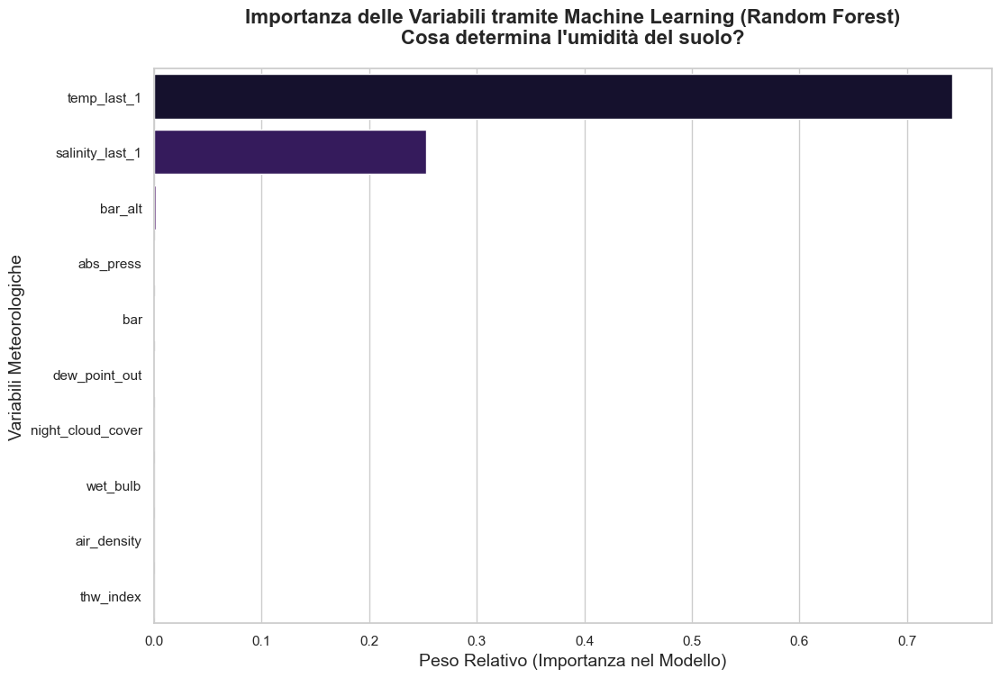


Top 5 variabili più importanti secondo il Machine Learning:
temp_last_1        0.741685
salinity_last_1    0.252702
bar_alt            0.001595
abs_press          0.001252
bar                0.000861
dtype: float64


In [33]:
X2 = df_clean.drop(columns=['moist_soil_last_1'])
y2 = df_clean['moist_soil_last_1']

train_mask2 = df_clean.index < '2025-07-01'
test_mask2 = df_clean.index >= '2025-07-01'

X2_train, y2_train = X2[train_mask], y2[train_mask]
X2_test, y2_test = X2[test_mask], y2[test_mask]


rf2 = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10, n_jobs=-1)
rf2.fit(X2_train, y2_train)

#valutazione sul test set
y2_pred=rf2.predict(X2_test)
mae2 = mean_absolute_error(y2_test, y2_pred)
r2_2 = r2_score(y2_test, y2_pred)

print(f"\n--- Performance sul Test Set ---")
print(f"R-quadro (R2): {r2_2:.3f} ")
print(f"Errore Medio Assoluto (MAE): {mae2:.2f} ")

# Estraiamo l'importanza delle singole variabili 
importances2 = pd.Series(rf2.feature_importances_, index=X2.columns).sort_values(ascending=False)

# Creiamo il grafico delle Top 10 variabili più importanti
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")
sns.barplot(x=importances2.head(10).values, y=importances2.head(10).index, palette='magma', hue=importances2.head(10).index, legend=False)

plt.title("Importanza delle Variabili tramite Machine Learning (Random Forest)\nCosa determina l'umidità del suolo?", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Peso Relativo (Importanza nel Modello)", fontsize=14)
plt.ylabel("Variabili Meteorologiche", fontsize=14)
plt.show()


print("\nTop 5 variabili più importanti secondo il Machine Learning:")
print(importances2.head(5))

\
**Perchè questo risultato?**
*temp_last_1* e *salinity_last_1* sono rispettivamente temperatura e salinità del suolo, esse non spiegano perchè il suolo è umido o asciutto, non sono parametri atmosferici, ma sono misurazioni che provengono dallo stesso sensore di *moist_soil_1*.

Ciò che è successo è il Data Leakage (questi due parametri non hanno potere predittivo sulla nostra variabile d'interesse, non ci aiutano a prevederla, il modello sta imparando a utilizzare le informazioni a cui non avrà accesso nelle previsioni del mondo reale), per ovviare a questo problema escludiamo queste due features dall'addestramento:


--- Performance sul Test Set ---
R-quadro (R2): 0.745 
Errore Medio Assoluto (MAE): 2.07 


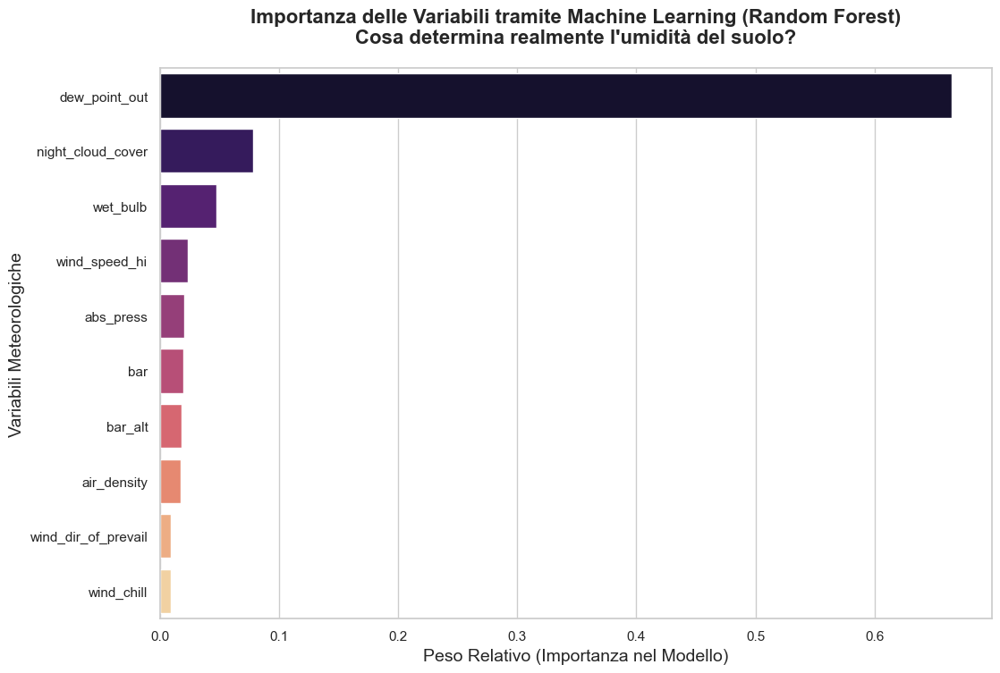


Top 5 variabili più importanti secondo il Machine Learning:
dew_point_out        0.664936
night_cloud_cover    0.078235
wet_bulb             0.047854
wind_speed_hi        0.023783
abs_press            0.020517
dtype: float64


In [34]:
X2 = df_clean.drop(columns=['moist_soil_last_1', 'temp_last_1','salinity_last_1'])
y2 = df_clean['moist_soil_last_1']

train_mask2 = df_clean.index < '2025-07-01'
test_mask2 = df_clean.index >= '2025-07-01'

X2_train, y2_train = X2[train_mask], y2[train_mask]
X2_test, y2_test = X2[test_mask], y2[test_mask]


rf2 = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10, n_jobs=-1)
rf2.fit(X2_train, y2_train)

#valutazione sul test set
y2_pred=rf2.predict(X2_test)
mae2 = mean_absolute_error(y2_test, y2_pred)
r2_2 = r2_score(y2_test, y2_pred)

print(f"\n--- Performance sul Test Set ---")
print(f"R-quadro (R2): {r2_2:.3f} ")
print(f"Errore Medio Assoluto (MAE): {mae2:.2f} ")

# Estraiamo l'importanza delle singole variabili 
importances2 = pd.Series(rf2.feature_importances_, index=X2.columns).sort_values(ascending=False)

# Creiamo il grafico delle Top 10 variabili più importanti
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")
sns.barplot(x=importances2.head(10).values, y=importances2.head(10).index, palette='magma', hue=importances2.head(10).index, legend=False)

plt.title("Importanza delle Variabili tramite Machine Learning (Random Forest)\nCosa determina realmente l'umidità del suolo?", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Peso Relativo (Importanza nel Modello)", fontsize=14)
plt.ylabel("Variabili Meteorologiche", fontsize=14)
plt.show()


print("\nTop 5 variabili più importanti secondo il Machine Learning:")
print(importances2.head(5))

1. **Il Punto di Rugiada** (dew_point_out - 63% di importanza):

   Il Punto di Rugiada è la temperatura alla quale l'aria diventa satura di vapore acqueo. Esso misura l'esatta quantità di umidità assoluta presente nell'atmosfera. Se l'aria è molto secca (punto di rugiada basso), essa "risucchierà" avidamente l'umidità dal terreno. Il modello ha scoperto che questo indicatore termodinamico è il primo fattore di essiccazione del Suo suolo.

2. **La Copertura Nuvolosa Notturna** (night_cloud_cover - 8.1%):

   Le nubi notturne agiscono come una "coperta" che impedisce al suolo di raffreddarsi rapidamente tramite irraggiamento verso lo spazio (prevenendo la formazione di rugiada e la condensazione sul terreno).

3. **Il Bulbo Umido** (wet_bulb - 7.3%):

   È un parametro intimamente legato al Punto di Rugiada e all'evaporazione dell'acqua nell'aria circostante.

4. **Le Raffiche di Vento** (wind_speed_hi - 2.2%):

   Il vento "spazza via" lo strato limite di aria umida che si forma sopra il terreno, accelerando meccanicamente l'essiccamento.


*E la pioggia che fine ha fatto?*
La pioggia influisce enormemente sull'umidità del suolo, ma nel grafico precedente non appare tra i parametri principali a causa dello Sparsity Bias.

In altre la pioggia viene vista come un fenomeno raro con il 93% di zeri, quindi piove solo nel 7% dei casi e nel restante 93% in cui non piove vi è in corso il fenomeno di asciugatura, l'algoritmo ha imparato quello che succede nella maggior parte del tempo.

Una soluzione è dividere la fase di asciugatura del terreno da quella di bagnatura:

--- Bagnatura Suolo ---
Eventi totali di pioggia analizzati: 6933
Metriche Test Set -> R2: -0.070 | MAE: 0.050


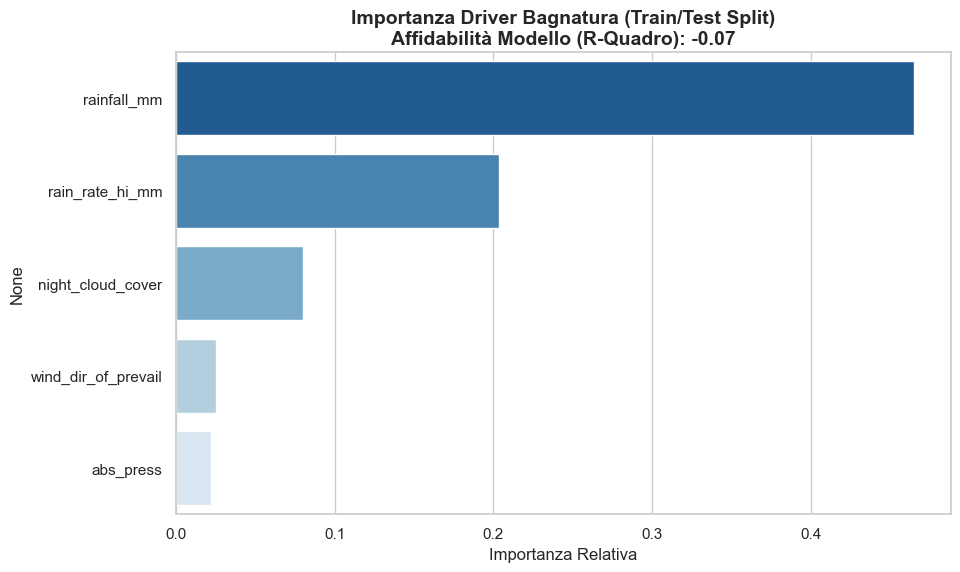

In [35]:
#variazione di umidita tra un'ora e l'altra
df_soil = df_clean.copy()
df_soil=df_soil.drop(columns=['temp_last_1', 'salinity_last_1'], errors='ignore')
df_soil['soil_delta'] = df_soil['moist_soil_last_1'].diff()

#seleziono solo i momenti in cui il suolo è bagnato, quindi con delta>0
wetting_events = df_soil[df_soil['soil_delta'] > 0]

if not wetting_events.empty:
    X_wet = wetting_events.drop(columns=['moist_soil_last_1', 'soil_delta', 'et'], errors='ignore')
    y_wet = wetting_events['soil_delta']
    
    #  (80% Train, 20% Test)
    # Usiamo un taglio percentuale invece di una data fissa per assicurarci 
    # che ci siano eventi di pioggia sia nel passato che nel "futuro" da testare.
    split_idx = int(len(X_wet) * 0.8)
    X_train_w, X_test_w = X_wet.iloc[:split_idx], X_wet.iloc[split_idx:]
    y_train_w, y_test_w = y_wet.iloc[:split_idx], y_wet.iloc[split_idx:]
    
    rf_wet = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=5, n_jobs=-1)
    rf_wet.fit(X_train_w, y_train_w)
    
    # Valutazione
    y_pred_w = rf_wet.predict(X_test_w)
    r2_w = r2_score(y_test_w, y_pred_w)
    mae_w = mean_absolute_error(y_test_w, y_pred_w)
    
    importances_wet = pd.Series(rf_wet.feature_importances_, index=X_train_w.columns).sort_values(ascending=False)
    
    print("--- Bagnatura Suolo ---")
    print(f"Eventi totali di pioggia analizzati: {len(wetting_events)}")
    print(f"Metriche Test Set -> R2: {r2_w:.3f} | MAE: {mae_w:.3f}")
    
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x=importances_wet.head(5).values, y=importances_wet.head(5).index, palette='Blues_r', hue=importances_wet.head(5).index, legend=False)
    plt.title(f"Importanza Driver Bagnatura (Train/Test Split)\nAffidabilità Modello (R-Quadro): {r2_w:.2f}", fontsize=14, fontweight='bold')
    plt.xlabel("Importanza Relativa", fontsize=12)
    plt.show()

Le variabili relative alla pioggia dominano la classifica dimostrano, come ci si aspetta, che la pioggia è responsabile del suolo bagnato.

Quindi con questo risultato e quello precedente su *et* abbiamo appurato che il Sole causa la perdita d'acqua e la Pioggia ne causa il ripristino.

Adesso generalizziamo, le tre grandi scoperte :

1. l'input dell'acqua viene dato dalla pioggia;

2. l'energia che fa sudare (evapotraspirazione) la pianta è data dal sole;

3. la velocità con cui l'acqua viene sottratta al suolo in assenza di pioggia è determinata principalmente da quanto l'aria è secca, misurata rigorosamente tramite il punto di rugiada.


Per decidere quando irrigare, il sistema dovrà eseguire quotidianamente questo calcolo (guardando alle 24 ore succesive):

1. lettura dello stato attuale, il sistema rileva l'umidità del suolo odierna;

2. valutazione delle previsioni meteo, se è prevista pioggia abbondante, l'irrigazione viene sospesa;

3. se non piove, il sistema valuta il sole e il punto di rugiada previsti per il giorno dopo, se i prevede una giornata con fortissima radiazione solare e aria molto secca (punto di rugiada basso), il modello calcolerà un crollo drastico dell'umidità del suolo;

4. di conseguenza, se l'umidità della sera successiva scende al di sotto della soglia critica di stress idrico allora il sistema manda il segnale per l'innaffiatura.